# 01 - Image analysis (Weeks 9-10)

**Dataset:** Car License Plate Detection, 433 PNG files with 471 reference
boxes. **Task:** locate the license plate in a photo and report its bounding
box (detection and localization track).

This notebook inspects the images before any pipeline design: formats, sizes,
histograms, noise, illumination, frequency content, the cost of reducing
resolution and gray levels, and the label quality of duplicate scenes. Every
figure is written to `experiments/figures/` and every number is reproducible
with `seed = 42`.

Display rule: all images are loaded through `src.data.load_image`, which
returns **RGB** (BGR is converted before display).


## 1. Load the dataset and the frozen split

In [1]:
%matplotlib inline
from itertools import combinations
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import data as datamod
from src import metrics

FIG_DIR = ROOT / "experiments" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 9, "axes.labelsize": 9})
SEED = 42

samples = datamod.discover_samples()
split = datamod.ensure_split(samples, seed=SEED)
canon = datamod.canonical_samples(samples)
dev = datamod.get_split_samples("dev", samples=samples, split=split)
test = datamod.get_split_samples("test", samples=samples, split=split)
groups = datamod.group_samples(samples)
samples_by_name = {sample.name: sample for sample in canon}
n_boxes = sum(len(sample.boxes) for sample in samples)
print(f"{len(samples)} files -> {len(canon)} unique scenes "
      f"| dev {len(dev)} / test {len(test)} | {n_boxes} reference boxes")
print(f"split file: {datamod.SPLIT_PATH.relative_to(ROOT)} | seed {split['seed']}")


433 files -> 299 unique scenes | dev 209 / test 90 | 471 reference boxes
split file: data\splits\dev_test.json | seed 42


## 2. Dataset overview and project criteria

In [2]:
format_counts = {}
for sample in samples:
    raw = cv2.imread(str(sample.image_path), cv2.IMREAD_UNCHANGED)
    channels = 1 if raw.ndim == 2 else raw.shape[2]
    key = f"{raw.dtype} / {channels} ch"
    format_counts[key] = format_counts.get(key, 0) + 1

formats = pd.DataFrame(
    {"files": pd.Series(format_counts)}
).sort_values("files", ascending=False)
formats["share"] = (formats["files"] / len(samples)).map(lambda value: f"{value:.1%}")

records = []
for sample in canon:
    gray = datamod.load_image(sample.image_path, color=False)
    residual = gray.astype(np.float32) - cv2.medianBlur(gray, 5).astype(np.float32)
    blurred = cv2.GaussianBlur(gray, (0, 0), 8)
    small = cv2.resize(blurred, (16, 16), interpolation=cv2.INTER_AREA)
    edges = cv2.Laplacian(gray, cv2.CV_32F)
    widths = sample.boxes[:, 2] - sample.boxes[:, 0]
    heights = sample.boxes[:, 3] - sample.boxes[:, 1]
    records.append(
        {
            "image": sample.name,
            "width": int(gray.shape[1]),
            "height": int(gray.shape[0]),
            "contrast": float(gray.std()),
            "mean": float(gray.mean()),
            "noise_sigma": float(residual.std()),
            "illum_range": float(int(small.max()) - int(small.min())),
            "blur_score": float(edges.var()),
            "n_gt": int(len(sample.boxes)),
            "plate_w": float(widths.max()),
            "plate_h": float(heights.max()),
        }
    )
stats = pd.DataFrame(records).set_index("image")

display(formats)
print("Image size and quality statistics over unique scenes:")
display(
    stats[["width", "height", "contrast", "noise_sigma", "illum_range", "blur_score"]]
    .describe()
    .loc[["min", "25%", "50%", "75%", "max"]]
    .round(2)
)

canon_boxes = np.concatenate([sample.boxes for sample in canon])
plate_widths = canon_boxes[:, 2] - canon_boxes[:, 0]
plate_heights = canon_boxes[:, 3] - canon_boxes[:, 1]
median_w = float(np.median(plate_widths))
median_h = float(np.median(plate_heights))
print(
    f"Plate size: median {median_w:.0f} x {median_h:.0f} px, "
    f"width p25/p75 = {np.percentile(plate_widths, 25):.0f}/"
    f"{np.percentile(plate_widths, 75):.0f} px"
)


,files,share
uint16 / 4 ch,315,72.7%
uint8 / 3 ch,110,25.4%
uint8 / 4 ch,8,1.8%


Image size and quality statistics over unique scenes:


,width,height,contrast,noise_sigma,illum_range,blur_score
min,225.0,141.0,31.03,4.45,74.0,146.28
25%,400.0,247.0,57.70,11.06,179.0,767.06
50%,400.0,268.0,65.11,13.60,205.0,1308.93
75%,400.0,307.0,72.86,16.04,224.5,1825.94
max,600.0,531.0,100.89,35.93,255.0,10557.96


Plate size: median 69 x 25 px, width p25/p75 = 38/114 px


In [3]:
low_contrast = float(stats["contrast"].quantile(0.05))
noise_p95 = float(stats["noise_sigma"].quantile(0.95))
illum_p95 = float(stats["illum_range"].quantile(0.95))
blur_p05 = float(stats["blur_score"].quantile(0.05))
n_multi = int((stats["n_gt"] > 1).sum())

criteria = pd.DataFrame(
    [
        {
            "criterion": "Size",
            "requirement": "At least 100 real images",
            "evidence": (
                f"{len(canon)} unique scenes ({len(samples)} files) "
                "after duplicate grouping"
            ),
            "status": "Met",
        },
        {
            "criterion": "Ground truth",
            "requirement": "A reference answer for every image",
            "evidence": f"{n_boxes} reference boxes; every annotation file has at least one",
            "status": "Met",
        },
        {
            "criterion": "Task difficulty",
            "requirement": "Decision needs object/background separation",
            "evidence": (
                "Output is a plate bounding box scored by IoU; plates must be "
                "separated from cars, road and vegetation"
            ),
            "status": "Met",
        },
        {
            "criterion": "Real-world mess",
            "requirement": "At least two of low contrast, uneven light, noise, blur",
            "evidence": (
                f"gray std p05 = {low_contrast:.1f}; "
                f"high-frequency sigma p95 = {noise_p95:.1f}; "
                f"16x16 illumination range p95 = {illum_p95:.0f}; "
                f"Laplacian variance p05 = {blur_p05:.0f}"
            ),
            "status": "Met",
        },
        {
            "criterion": "Licence",
            "requirement": "Public, academic use",
            "evidence": "CC0 1.0 (see data/raw/LICENSE.md)",
            "status": "Met",
        },
        {
            "criterion": "Feasibility",
            "requirement": "Full test set < 10 min on free Colab CPU",
            "evidence": (
                "Both Week-10 baselines process 209 dev scenes "
                "in a few seconds"
            ),
            "status": "Met",
        },
        {
            "criterion": "Not a toy",
            "requirement": "No sample/synthetic data, not one threshold or filter",
            "evidence": (
                "299 real street photos; both spec baselines fail "
                "(mean IoU about 0.05), so a multi-stage pipeline is required"
            ),
            "status": "Met",
        },
    ]
)
display(criteria.set_index("criterion"))


,requirement,evidence,status
criterion,,,
Size,At least 100 real images,299 unique scenes (433 files) after duplicate ...,Met
Ground truth,A reference answer for every image,471 reference boxes; every annotation file has...,Met
Task difficulty,Decision needs object/background separation,Output is a plate bounding box scored by IoU; ...,Met
Real-world mess,"At least two of low contrast, uneven light, no...",gray std p05 = 47.4; high-frequency sigma p95 ...,Met
Licence,"Public, academic use",CC0 1.0 (see data/raw/LICENSE.md),Met
Feasibility,Full test set < 10 min on free Colab CPU,Both Week-10 baselines process 209 dev scenes ...,Met
Not a toy,"No sample/synthetic data, not one threshold or...",299 real street photos; both spec baselines fa...,Met


**Observations.** The archive mixes 8-bit RGB, 8-bit RGBA and 16-bit RGBA
PNGs, so a single loader is mandatory. Sizes vary from 225 to 600 px wide.
Plates are small: the median reference box is only about 69 x 25 px, and the
lower quartile is about 38 px wide.

## 3. Typical and difficult images

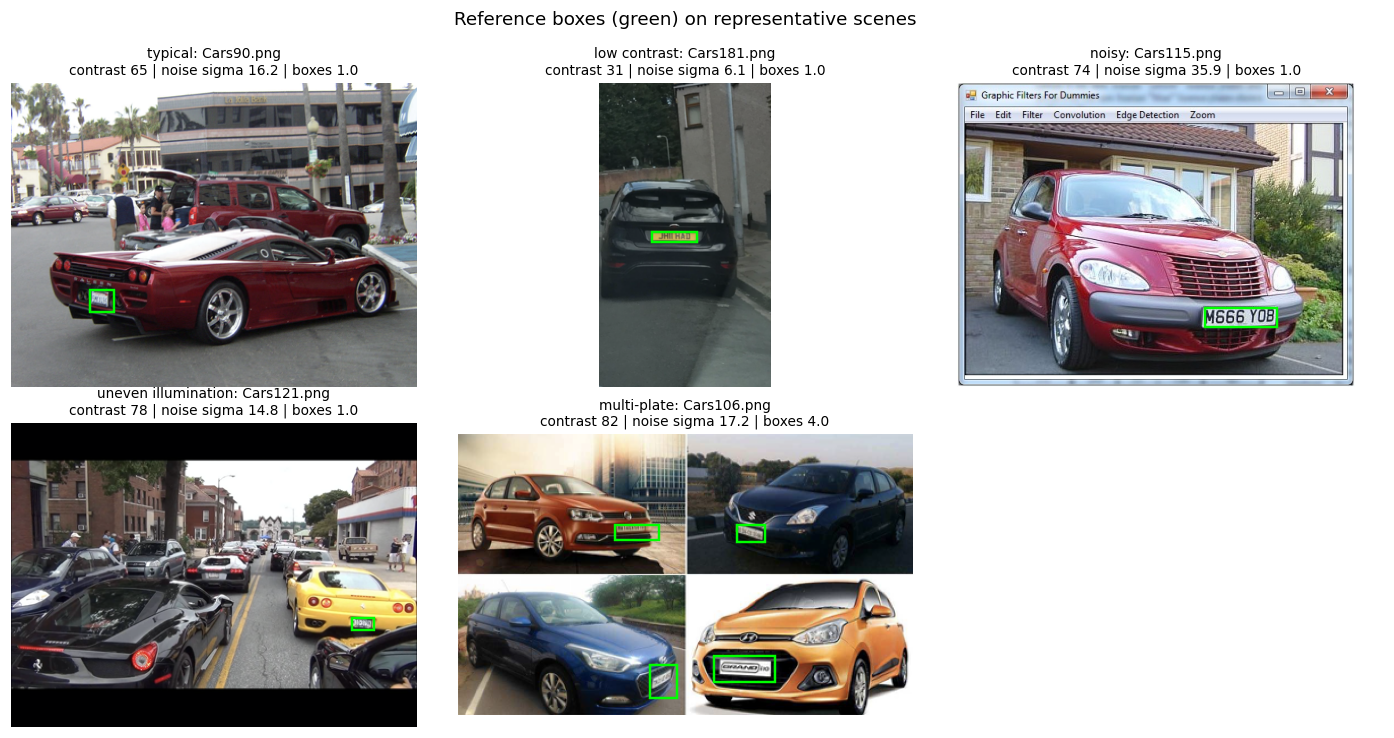

{'typical': 'Cars90.png', 'low contrast': 'Cars181.png', 'noisy': 'Cars115.png', 'uneven illumination': 'Cars121.png', 'multi-plate': 'Cars106.png'}


In [4]:
chosen = {}
chosen["typical"] = stats["contrast"].sub(stats["contrast"].median()).abs().idxmin()

def pick(column, ascending, used):
    for name in stats[column].sort_values(ascending=ascending).index:
        if name not in used:
            return name
    return None

chosen["low contrast"] = pick("contrast", True, set(chosen.values()))
chosen["noisy"] = pick("noise_sigma", False, set(chosen.values()))
chosen["uneven illumination"] = pick("illum_range", False, set(chosen.values()))
chosen["multi-plate"] = pick("n_gt", False, set(chosen.values()))

figure, axes = plt.subplots(2, 3, figsize=(13, 6.8))
for axis, label in zip(axes.ravel(), chosen):
    sample = samples_by_name[chosen[label]]
    row = stats.loc[sample.name]
    axis.imshow(datamod.load_image(sample.image_path, color=True))
    for box in sample.boxes:
        axis.add_patch(
            Rectangle(
                (box[0], box[1]),
                box[2] - box[0],
                box[3] - box[1],
                fill=False,
                edgecolor="lime",
                linewidth=1.6,
            )
        )
    axis.set_title(
        f"{label}: {sample.name}\n"
        f"contrast {row['contrast']:.0f} | noise sigma {row['noise_sigma']:.1f} | "
        f"boxes {row['n_gt']}"
    )
    axis.axis("off")
axes.ravel()[-1].axis("off")
figure.suptitle("Reference boxes (green) on representative scenes")
figure.tight_layout()
figure.savefig(FIG_DIR / "01_dataset_gallery.png", dpi=150, bbox_inches="tight")
plt.show()
print(chosen)


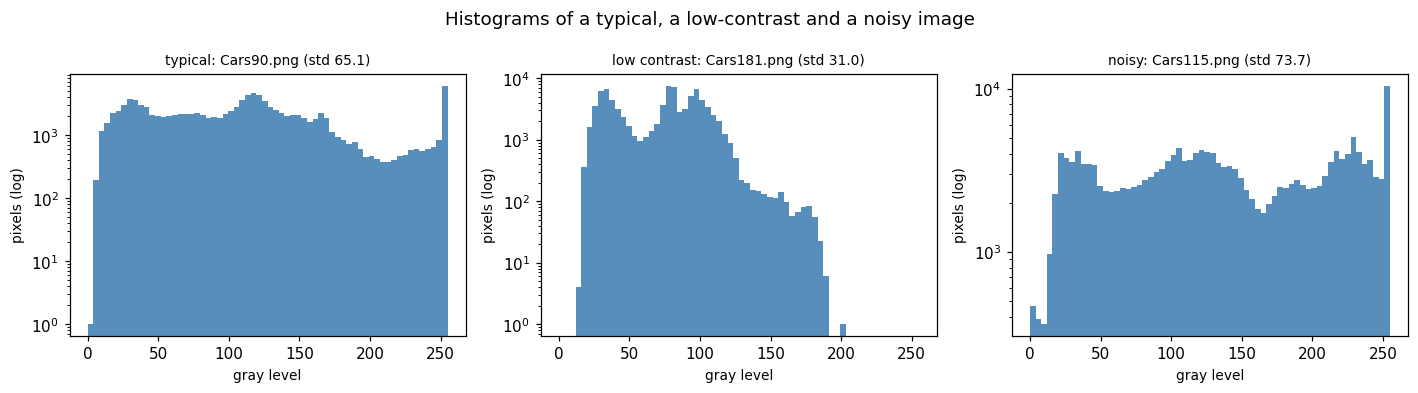

In [5]:
figure, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for axis, label in zip(axes, ["typical", "low contrast", "noisy"]):
    sample = samples_by_name[chosen[label]]
    gray = datamod.load_image(sample.image_path, color=False)
    axis.hist(gray.ravel(), bins=64, range=(0, 255), color="steelblue", alpha=0.9, log=True)
    axis.set_title(f"{label}: {sample.name} (std {gray.std():.1f})")
    axis.set_xlabel("gray level")
    axis.set_ylabel("pixels (log)")
figure.suptitle("Histograms of a typical, a low-contrast and a noisy image")
figure.tight_layout()
figure.savefig(FIG_DIR / "02_histograms.png", dpi=150, bbox_inches="tight")
plt.show()


The low-contrast image occupies a narrow band of gray levels, so a fixed
global threshold has little signal to work with. The noisy image has a broad
histogram, but its spread is partly random fluctuation rather than object
contrast.

## 4. Illumination across the image

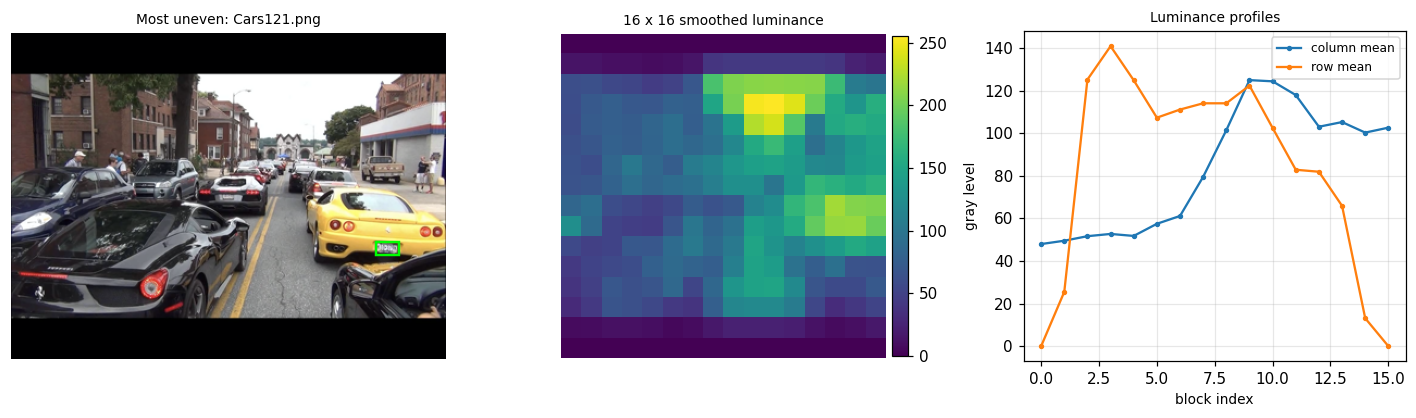

smoothed block range in this image: 255 gray levels; p95 across the dataset: 244


In [6]:
sample = samples_by_name[chosen["uneven illumination"]]
rgb = datamod.load_image(sample.image_path, color=True)
gray = datamod.load_image(sample.image_path, color=False)
blurred = cv2.GaussianBlur(gray, (0, 0), 8)
small = cv2.resize(blurred, (16, 16), interpolation=cv2.INTER_AREA)

figure, axes = plt.subplots(
    1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.25, 1.0, 1.1]}
)
axes[0].imshow(rgb)
for box in sample.boxes:
    axes[0].add_patch(
        Rectangle(
            (box[0], box[1]),
            box[2] - box[0],
            box[3] - box[1],
            fill=False,
            edgecolor="lime",
            linewidth=1.6,
        )
    )
axes[0].set_title(f"Most uneven: {sample.name}")
axes[0].axis("off")
image = axes[1].imshow(small, cmap="viridis")
axes[1].set_title("16 x 16 smoothed luminance")
axes[1].axis("off")
figure.colorbar(image, ax=axes[1], fraction=0.046, pad=0.02)
axes[2].plot(small.mean(axis=0), marker="o", ms=2.5, label="column mean")
axes[2].plot(small.mean(axis=1), marker="o", ms=2.5, label="row mean")
axes[2].set_title("Luminance profiles")
axes[2].set_xlabel("block index")
axes[2].set_ylabel("gray level")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)
figure.tight_layout()
figure.savefig(FIG_DIR / "03_illumination.png", dpi=150, bbox_inches="tight")
plt.show()
print(
    f"smoothed block range in this image: {int(small.max()) - int(small.min())} gray levels; "
    f"p95 across the dataset: {illum_p95:.0f}"
)


Smooth luminance changes of tens of gray levels across one scene make a
single global threshold unsafe: the same plate can fall on both sides of the
threshold depending on where it sits. This motivates illumination correction or
adaptive thresholding later.

## 5. Noise

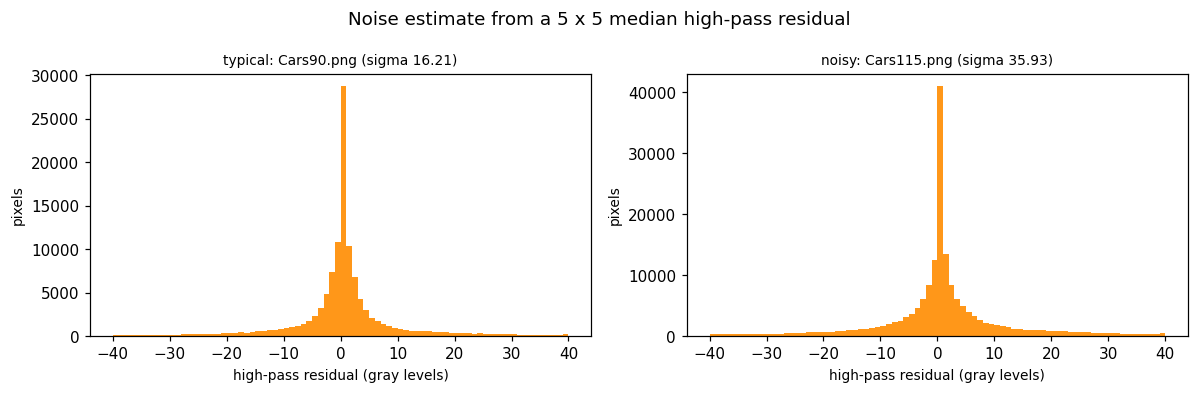

,residual_sigma,pixels_at_0,pixels_at_255
image,,,
Cars90.png,16.207199,0.0000,0.0424
Cars115.png,35.932201,0.0001,0.0136


residual sigma p95 over unique scenes: 21.37


In [7]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.6))
noise_rows = []
for axis, label in zip(axes, ["typical", "noisy"]):
    sample = samples_by_name[chosen[label]]
    gray = datamod.load_image(sample.image_path, color=False)
    residual = gray.astype(np.float32) - cv2.medianBlur(gray, 5).astype(np.float32)
    axis.hist(residual.ravel(), bins=80, range=(-40, 40), color="darkorange", alpha=0.9)
    axis.set_title(f"{label}: {sample.name} (sigma {residual.std():.2f})")
    axis.set_xlabel("high-pass residual (gray levels)")
    axis.set_ylabel("pixels")
    noise_rows.append(
        {
            "image": sample.name,
            "residual_sigma": residual.std(),
            "pixels_at_0": float((gray == 0).mean()),
            "pixels_at_255": float((gray == 255).mean()),
        }
    )
figure.suptitle("Noise estimate from a 5 x 5 median high-pass residual")
figure.tight_layout()
figure.savefig(FIG_DIR / "04_noise.png", dpi=150, bbox_inches="tight")
plt.show()
display(pd.DataFrame(noise_rows).set_index("image").round(4))
print(f"residual sigma p95 over unique scenes: {noise_p95:.2f}")


The residual includes genuine texture and edges, so it is an upper bound on
sensor noise. It is still large enough (up to about 36 gray levels) that
smoothing must be chosen from evidence (mean vs Gaussian vs median) rather than
by habit.

## 6. Frequency content

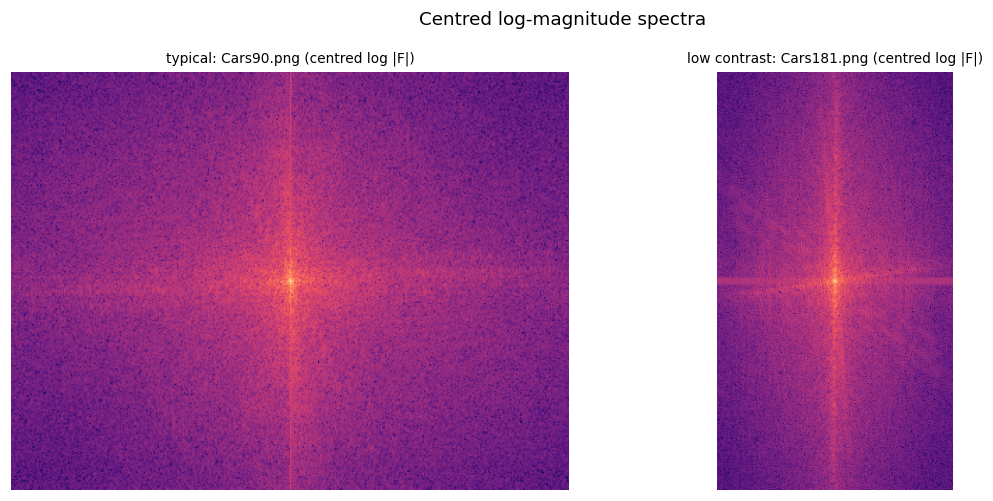

,low_band,mid_band,high_band
image,,,
Cars90.png,0.9414,0.0498,0.0088
Cars181.png,0.9631,0.0307,0.0061


In [8]:
def log_spectrum(gray):
    spectrum = np.fft.fftshift(np.fft.fft2(gray.astype(np.float32)))
    magnitude = np.log1p(np.abs(spectrum))
    return spectrum, magnitude


figure, axes = plt.subplots(1, 2, figsize=(11, 4.6))
energy_rows = []
for axis, label in zip(axes, ["typical", "low contrast"]):
    sample = samples_by_name[chosen[label]]
    gray = datamod.load_image(sample.image_path, color=False)
    spectrum, magnitude = log_spectrum(gray)
    axis.imshow(magnitude, cmap="magma")
    axis.set_title(f"{label}: {sample.name} (centred log |F|)")
    axis.axis("off")
    height, width = gray.shape
    yy, xx = np.mgrid[0:height, 0:width]
    radius = np.sqrt((yy - height / 2) ** 2 + (xx - width / 2) ** 2)
    r_max = min(height, width) / 2
    power = np.abs(spectrum) ** 2
    total = power.sum()
    energy_rows.append(
        {
            "image": sample.name,
            "low_band": float(power[radius < 0.1 * r_max].sum() / total),
            "mid_band": float(
                power[(radius >= 0.1 * r_max) & (radius <= 0.5 * r_max)].sum()
                / total
            ),
            "high_band": float(power[radius > 0.5 * r_max].sum() / total),
        }
    )
figure.suptitle("Centred log-magnitude spectra")
figure.tight_layout()
figure.savefig(FIG_DIR / "05_spectra.png", dpi=150, bbox_inches="tight")
plt.show()
display(pd.DataFrame(energy_rows).set_index("image").round(4))


The low-contrast image concentrates relatively more energy near the
origin (low frequencies), while the typical image keeps more high-frequency
energy from plate characters, edges and texture. The strong cross in both
spectra comes from horizontal and vertical structures (road markings, car
edges, buildings). A high-pass or band-pass stage must therefore compete with
background edges, not just noise.

## 7. Resolution and gray-level limits

Three single-plate images with plate sizes close to the dataset median are
degraded in two ways:

1. **Spatial resolution:** resize by a scale factor with area interpolation.
2. **Gray levels:** quantise to 256, 32, 16, 8, 4 or 2 levels.

The plate crop is compared with its original using normalised cross-correlation
(NCC) and ROI PSNR. The task is called possible while **all three** plates keep
NCC >= 0.90 and ROI PSNR >= 17 dB, i.e. the plate structure is still clearly
present.

In [9]:
single_box = [sample for sample in canon if len(sample.boxes) == 1]
def plate_distance(sample):
    box = sample.boxes[0]
    width = box[2] - box[0]
    height = box[3] - box[1]
    return abs(width - median_w) + abs(height - median_h)

degradation_images = sorted(single_box, key=plate_distance)[:3]
print("Images used:", [sample.name for sample in degradation_images])
plate_sizes = [
    tuple(np.round(s.boxes[0][2:] - s.boxes[0][:2]).astype(int))
    for s in degradation_images
]
print("Plate sizes:", plate_sizes)

SCALES = [1.0, 0.75, 0.5, 0.375, 0.25, 0.125]
LEVELS = [256, 32, 16, 8, 4, 2]
NCC_MIN = 0.90
PSNR_MIN = 17.0


def ncc(reference, test):
    a = reference.astype(np.float64)
    b = test.astype(np.float64)
    a -= a.mean()
    b -= b.mean()
    denominator = np.sqrt((a * a).sum() * (b * b).sum())
    return float((a * b).sum() / denominator) if denominator > 0 else 0.0


def roi_scores(gray, box, scale=None, levels=None):
    x1, y1, x2, y2 = (int(round(value)) for value in box)
    reference = gray[y1:y2, x1:x2]
    if scale is not None:
        small = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        sx1, sy1, sx2, sy2 = (int(round(value * scale)) for value in (x1, y1, x2, y2))
        if sx2 <= sx1 or sy2 <= sy1:
            return float("nan"), float("nan")
        crop = cv2.resize(
            small[sy1:sy2, sx1:sx2],
            (reference.shape[1], reference.shape[0]),
            interpolation=cv2.INTER_CUBIC,
        )
    else:
        quantised = (
            (gray.astype(np.int32) * levels // 256) * (255 // (levels - 1))
        ).astype(np.uint8)
        crop = quantised[y1:y2, x1:x2]
    score = metrics.psnr(reference, crop)
    return (99.0 if np.isinf(score) else float(score)), ncc(reference, crop)


def degrade_scale_image(gray, scale):
    return cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)


def degrade_levels_image(gray, levels):
    return ((gray.astype(np.int32) * levels // 256) * (255 // (levels - 1))).astype(np.uint8)


scale_detail = []
level_detail = []
for sample in degradation_images:
    gray = datamod.load_image(sample.image_path, color=False)
    box = sample.boxes[0]
    for scale in SCALES:
        psnr_value, ncc_value = roi_scores(gray, box, scale=scale)
        scale_detail.append(
            {"image": sample.name, "scale": scale, "ncc": ncc_value, "psnr": psnr_value}
        )
    for levels in LEVELS:
        psnr_value, ncc_value = roi_scores(gray, box, levels=levels)
        level_detail.append(
            {"image": sample.name, "levels": levels, "ncc": ncc_value, "psnr": psnr_value}
        )

scale_detail = pd.DataFrame(scale_detail)
level_detail = pd.DataFrame(level_detail)
scale_summary = (
    scale_detail.groupby("scale")
    .agg(min_ncc=("ncc", "min"), min_psnr=("psnr", "min"))
    .reset_index()
)
scale_summary["pass"] = (scale_summary["min_ncc"] >= NCC_MIN) & (
    scale_summary["min_psnr"] >= PSNR_MIN
)
level_summary = (
    level_detail.groupby("levels")
    .agg(min_ncc=("ncc", "min"), min_psnr=("psnr", "min"))
    .reset_index()
)
level_summary["pass"] = (level_summary["min_ncc"] >= NCC_MIN) & (
    level_summary["min_psnr"] >= PSNR_MIN
)

print("NCC per image and scale:")
display(scale_detail.pivot(index="image", columns="scale", values="ncc").round(3))
display(scale_summary.round(3))
print("Gray levels:")
display(level_detail.pivot(index="image", columns="levels", values="ncc").round(3))
display(level_summary.round(3))

passing_scales = scale_summary.loc[scale_summary["pass"], "scale"]
passing_levels = level_summary.loc[level_summary["pass"], "levels"]
lowest_scale = float(passing_scales.min()) if len(passing_scales) else float("nan")
lowest_levels = int(passing_levels.min()) if len(passing_levels) else 0
mean_w = float(np.mean([(s.boxes[0][2] - s.boxes[0][0]) for s in degradation_images]))
print(
    f"Lowest passing scale: {lowest_scale:g} "
    f"(median plate about {mean_w * lowest_scale:.0f} px wide); "
    f"lowest passing gray-level count: {lowest_levels}"
)


Images used: ['Cars233.png', 'Cars186.png', 'Cars206.png']
Plate sizes: [(np.int64(70), np.int64(23)), (np.int64(67), np.int64(23)), (np.int64(69), np.int64(21))]
NCC per image and scale:


scale,0.125,0.250,0.375,0.500,0.750,1.000
image,,,,,,
Cars186.png,0.611,0.789,0.882,0.921,0.977,1.0
Cars206.png,0.447,0.767,0.788,0.881,0.944,1.0
Cars233.png,0.696,0.751,0.854,0.830,0.947,1.0


,scale,min_ncc,min_psnr,pass
0,0.125,0.447,10.254,False
1,0.250,0.751,12.981,False
2,0.375,0.788,13.557,False
3,0.500,0.830,15.815,False
4,0.750,0.944,18.625,True
5,1.000,1.000,99.000,True


Gray levels:


levels,2,4,8,16,32,256
image,,,,,,
Cars186.png,0.797,0.950,0.990,0.997,0.999,1.0
Cars206.png,0.929,0.982,0.995,0.999,1.000,1.0
Cars233.png,0.834,0.957,0.985,0.996,0.999,1.0


,levels,min_ncc,min_psnr,pass
0,2,0.797,9.580,False
1,4,0.950,17.664,True
2,8,0.985,25.801,True
3,16,0.996,31.710,True
4,32,0.999,35.705,True
5,256,1.000,99.000,True


Lowest passing scale: 0.75 (median plate about 51 px wide); lowest passing gray-level count: 4


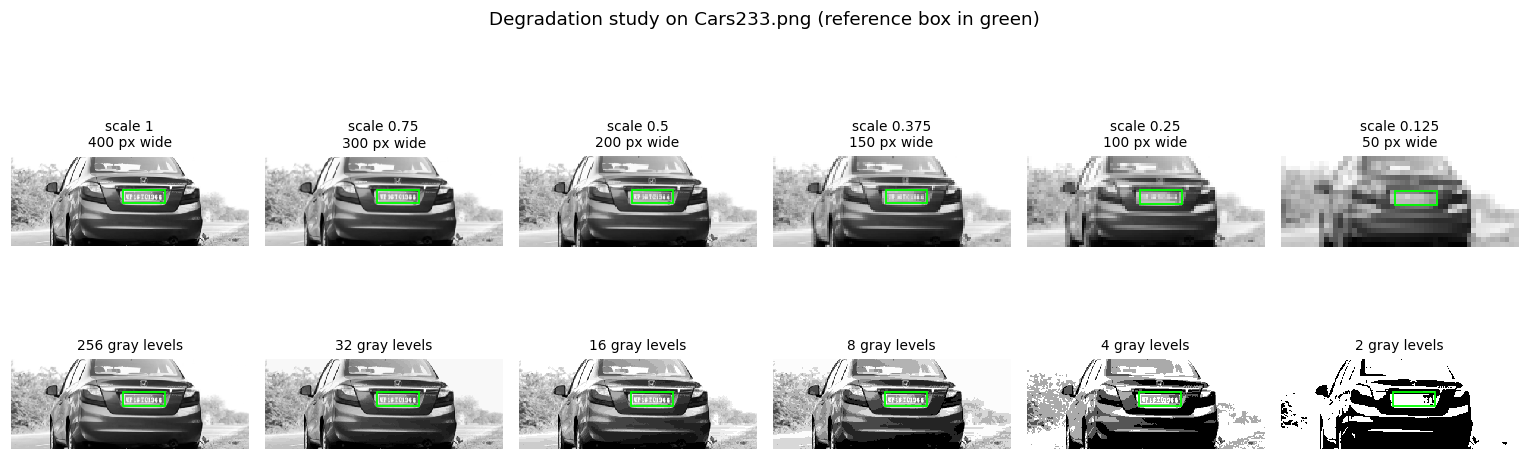

In [10]:
demo = degradation_images[0]
gray = datamod.load_image(demo.image_path, color=False)
box = demo.boxes[0]

figure, axes = plt.subplots(2, 6, figsize=(14, 5.2))
for axis, scale in zip(axes[0], SCALES):
    image = degrade_scale_image(gray, scale)
    axis.imshow(image, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    scaled = box * scale
    axis.add_patch(
        Rectangle(
            (scaled[0], scaled[1]),
            scaled[2] - scaled[0],
            scaled[3] - scaled[1],
            fill=False,
            edgecolor="lime",
            linewidth=1.2,
        )
    )
    axis.set_title(f"scale {scale:g}\n{int(gray.shape[1] * scale)} px wide")
    axis.axis("off")
for axis, levels in zip(axes[1], LEVELS):
    image = degrade_levels_image(gray, levels)
    axis.imshow(image, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    axis.add_patch(
        Rectangle(
            (box[0], box[1]),
            box[2] - box[0],
            box[3] - box[1],
            fill=False,
            edgecolor="lime",
            linewidth=1.2,
        )
    )
    axis.set_title(f"{levels} gray levels")
    axis.axis("off")
figure.suptitle(f"Degradation study on {demo.name} (reference box in green)")
figure.tight_layout()
figure.savefig(FIG_DIR / "06_resolution_levels.png", dpi=150, bbox_inches="tight")
plt.show()


**Conclusion.** At native resolution the plate is intact. At 75 % scale
(plate about 52 px wide) all three plates still pass the criterion. At 50 %
(about 35 px) one or more plates fall below NCC 0.90, and at 12.5 % the plate is
no longer reliably present. Reducing gray levels is more forgiving: 4 levels
(2 bits) still pass, while 2 levels destroy the internal contrast. The analysis
therefore fixes a design constraint: **process at native resolution; do not
downscale below 0.75**.

## 8. Duplicate scenes and label noise

duplicate groups: 85; files: 219
groups whose copies disagree on the plate count: 2
matched-box IoU between copies: mean 0.801, median 0.825, p10 0.671, below 0.50 3.4%, below 0.75 27.1%


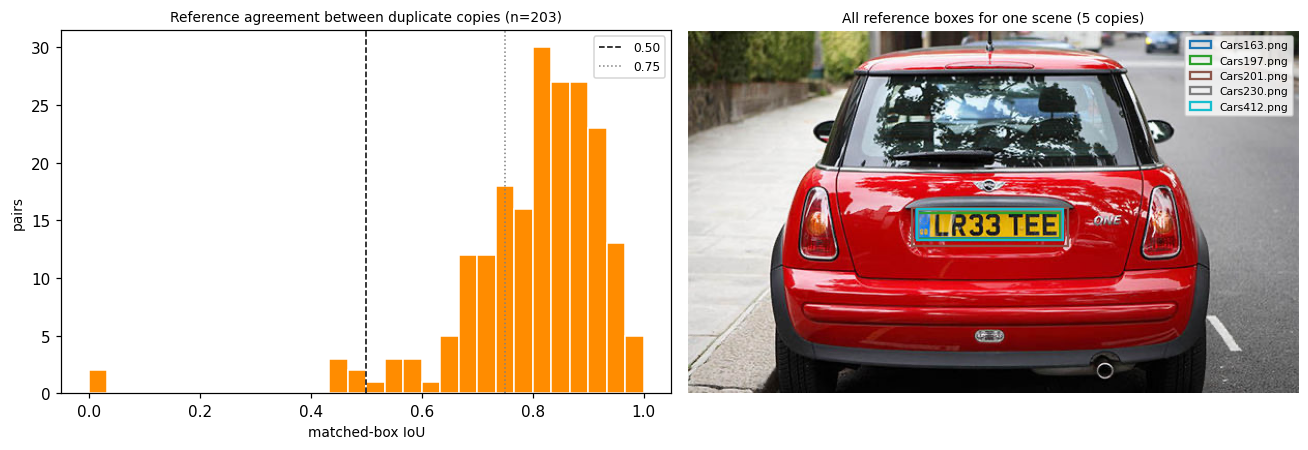

example group: ['Cars163.png', 'Cars197.png', 'Cars201.png', 'Cars230.png', 'Cars412.png']


In [11]:
duplicate_groups = [members for members in groups.values() if len(members) > 1]
count_mismatch = sum(
    1 for members in duplicate_groups if len({len(item.boxes) for item in members}) > 1
)
pair_ious = []
for members in duplicate_groups:
    for first, second in combinations(members, 2):
        for box in first.boxes:
            pair_ious.append(max(metrics.iou_box(box, other) for other in second.boxes))
pair_ious = np.asarray(pair_ious)

duplicate_files = sum(len(members) for members in duplicate_groups)
print(f"duplicate groups: {len(duplicate_groups)}; files: {duplicate_files}")
print(f"groups whose copies disagree on the plate count: {count_mismatch}")
print(
    f"matched-box IoU between copies: mean {pair_ious.mean():.3f}, "
    f"median {np.median(pair_ious):.3f}, p10 {np.percentile(pair_ious, 10):.3f}, "
    f"below 0.50 {np.mean(pair_ious < 0.5):.1%}, below 0.75 {np.mean(pair_ious < 0.75):.1%}"
)

example = max(
    (
        members
        for members in duplicate_groups
        if len({len(item.boxes) for item in members}) == 1
    ),
    key=len,
)
image = datamod.load_image(example[0].image_path, color=True)
figure, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(pair_ious, bins=30, range=(0, 1), color="darkorange", edgecolor="white")
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1, label="0.50")
axes[0].axvline(0.75, color="gray", linestyle=":", linewidth=1, label="0.75")
axes[0].set_title(f"Reference agreement between duplicate copies (n={len(pair_ious)})")
axes[0].set_xlabel("matched-box IoU")
axes[0].set_ylabel("pairs")
axes[0].legend(fontsize=8)
axes[1].imshow(image)
colors = plt.cm.tab10(np.linspace(0, 1, len(example)))
for member, color in zip(example, colors):
    for index, box in enumerate(member.boxes):
        axes[1].add_patch(
            Rectangle(
                (box[0], box[1]),
                box[2] - box[0],
                box[3] - box[1],
                fill=False,
                edgecolor=color,
                linewidth=1.5,
                label=member.name if index == 0 else None,
            )
        )
axes[1].legend(fontsize=7, loc="upper right")
axes[1].set_title(f"All reference boxes for one scene ({len(example)} copies)")
axes[1].axis("off")
figure.tight_layout()
figure.savefig(FIG_DIR / "07_duplicate_labels.png", dpi=150, bbox_inches="tight")
plt.show()
print("example group:", [member.name for member in example])


**Decision.** The split is built on duplicate groups, one canonical copy
represents each group, and 134 redundant files are excluded from evaluation.
Even with a perfect detector, the measured IoU is limited by roughly 0.17 of
label jitter, which must be stated with the results.

## 9. Findings and design decisions

In [12]:
findings = pd.DataFrame(
    [
        {
            "finding": "Mixed PNG encodings",
            "evidence": "315 RGBA uint16, 110 RGB uint8, 8 RGBA uint8",
            "decision": "Single loader: 16->8 bit, drop alpha, RGB or grayscale uint8 0-255",
        },
        {
            "finding": "Duplicate scenes with label jitter",
            "evidence": (
                f"433 files -> 299 scenes; matched-box median IoU "
                f"{np.median(pair_ious):.3f}, "
                f"{np.mean(pair_ious < 0.5):.1%} below 0.5"
            ),
            "decision": (
                "Split duplicate groups, keep one canonical copy, "
                "report the label-noise ceiling"
            ),
        },
        {
            "finding": "Plates are small and variable",
            "evidence": f"median {median_w:.0f} x {median_h:.0f} px; width p25/p75 "
                        f"{np.percentile(plate_widths, 25):.0f}/"
                        f"{np.percentile(plate_widths, 75):.0f} px",
            "decision": (
                "Multi-scale candidates, area and aspect filtering, "
                "no fixed pixel thresholds"
            ),
        },
        {
            "finding": "Low contrast in a tail of images",
            "evidence": f"gray std p05 = {low_contrast:.1f}",
            "decision": "Test gamma and CLAHE enhancement before edge detection",
        },
        {
            "finding": "Uneven illumination",
            "evidence": f"16x16 smoothed block range p95 = {illum_p95:.0f} gray levels",
            "decision": (
                "Background correction or adaptive thresholding; "
                "do not rely on one global threshold"
            ),
        },
        {
            "finding": "Visible noise",
            "evidence": f"5x5 median residual sigma p95 = {noise_p95:.1f}",
            "decision": (
                "Compare mean, Gaussian and median smoothing under "
                "controlled Gaussian and salt-and-pepper noise"
            ),
        },
        {
            "finding": "Strong high-frequency background structure",
            "evidence": "spectra show energy on both axes from road, cars and vegetation",
            "decision": (
                "Use direction-specific Sobel/LoG edges and wide horizontal "
                "closing to isolate plate character rows"
            ),
        },
        {
            "finding": "Resolution and gray-level limits",
            "evidence": (
                f"lowest passing scale {lowest_scale:g}; "
                f"lowest passing gray levels {lowest_levels}"
            ),
            "decision": (
                "Process at native resolution, never below 0.75 scale; "
                "keep at least 4 gray levels"
            ),
        },
        {
            "finding": "Raw-intensity baselines fail",
            "evidence": "dev mean IoU 0.058 (fixed threshold) and 0.052 (Otsu + opening)",
            "decision": (
                "Pipeline A starts from gradient magnitude and morphology, "
                "not global intensity"
            ),
        },
        {
            "finding": "Multiple plates per scene",
            "evidence": f"{n_multi} unique scenes contain 2-6 plates",
            "decision": (
                "Pipeline must return several candidates; use greedy matching "
                "and count error as secondary metric"
            ),
        },
    ]
)
display(findings.set_index("finding"))

lines = ["# Week 10 findings and design decisions", ""]
for _, row in findings.iterrows():
    lines += [
        f"## {row['finding']}",
        "",
        f"**Evidence:** {row['evidence']}",
        "",
        f"**Decision:** {row['decision']}",
        "",
    ]
findings_path = ROOT / "experiments" / "week10_findings.md"
findings_path.write_text("\n".join(lines), encoding="utf-8")
print(f"written: {findings_path.relative_to(ROOT)}")
print(f"figures written to {FIG_DIR.relative_to(ROOT)}")


,evidence,decision
finding,,
Mixed PNG encodings,"315 RGBA uint16, 110 RGB uint8, 8 RGBA uint8","Single loader: 16->8 bit, drop alpha, RGB or g..."
Duplicate scenes with label jitter,433 files -> 299 scenes; matched-box median Io...,"Split duplicate groups, keep one canonical cop..."
Plates are small and variable,median 69 x 25 px; width p25/p75 38/114 px,"Multi-scale candidates, area and aspect filter..."
Low contrast in a tail of images,gray std p05 = 47.4,Test gamma and CLAHE enhancement before edge d...
Uneven illumination,16x16 smoothed block range p95 = 244 gray levels,Background correction or adaptive thresholding...
Visible noise,5x5 median residual sigma p95 = 21.4,"Compare mean, Gaussian and median smoothing un..."
Strong high-frequency background structure,"spectra show energy on both axes from road, ca...",Use direction-specific Sobel/LoG edges and wid...
Resolution and gray-level limits,lowest passing scale 0.75; lowest passing gray...,"Process at native resolution, never below 0.75..."
Raw-intensity baselines fail,dev mean IoU 0.058 (fixed threshold) and 0.052...,Pipeline A starts from gradient magnitude and ...


written: experiments\week10_findings.md
figures written to experiments\figures


## Week 10 checkpoint summary

- Image analysis: formats, sizes, histograms, illumination, noise, spectra,
  resolution and gray-level limits - all measured and illustrated.
- Data preparation: duplicate-aware 70/30 split (209 dev / 90 test scenes),
  one canonical copy per scene, ground truth parsed from Supervisely-style JSON.
- Metrics: MSE, PSNR, mask IoU, box IoU, count error - unit-tested by hand.
- Baselines: fixed threshold 127 and Otsu + 3x3 opening, evaluated on the dev
  split (mean bbox IoU 0.058 and 0.052). The test split is still untouched.

Next (Weeks 11-12): implement Pipelines A, B and C for detection and
localization, with NumPy implementations checked against OpenCV.
